# 4. Skema 2: LSTM + FastText Embedding (Pembagian Data 80/20)
**Saran Deep Learning:** Akurasi training dan testing ≥ 92%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | LSTM (Long Short-Term Memory) |
| Ekstraksi Fitur | FastText Indonesian Embeddings (128-dim) |
| Pembagian Data | 80% Train / 20% Test |
| Target Akurasi | ≥ 92% (train dan test) |

In [ ]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding, LSTM, Dense, Dropout,
                                      SpatialDropout1D)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
from gensim.models import FastText

os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

print(f"TensorFlow version: {tf.__version__}")
df = pd.read_csv('data/clean_reviews.csv')
print(f"Loaded {len(df)} reviews")

In [2]:
# Cell 2: Label encoding and 80/20 split
label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)
df['content_clean'] = df['content_clean'].fillna('')

X = df['content_clean'].tolist()
y = df['label_enc'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Split: 80% train / 20% test")

Train: 6210 | Test: 1553
Split: 80% train / 20% test


In [3]:
# Cell 3: Tokenization + padding
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_WORDS, len(tokenizer.word_index)) + 1
print(f"Vocabulary size: {vocab_size}")
print(f"X_train shape: {X_train_pad.shape}")
print(f"X_test shape:  {X_test_pad.shape}")

# Save tokenizer (shared with Scheme 3)
joblib.dump(tokenizer, 'models/tokenizer.pkl')
print("Tokenizer saved to models/tokenizer.pkl")

Vocabulary size: 8533
X_train shape: (6210, 100)
X_test shape:  (1553, 100)
Tokenizer saved to models/tokenizer.pkl


In [4]:
# Cell 4: Train FastText embeddings on corpus
EMBED_DIM = 128

# Tokenize into word lists for gensim
sentences = [text.split() for text in X_train]

print("Training FastText embeddings...")
ft_model = FastText(
    sentences=sentences,
    vector_size=EMBED_DIM,
    window=5,
    min_count=1,
    workers=4,
    epochs=15
)
ft_model.save('models/fasttext_model.bin')
print(f"FastText trained. Vocab size: {len(ft_model.wv)}")

# Build embedding matrix
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
found = 0
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size and word in ft_model.wv:
        embedding_matrix[idx] = ft_model.wv[word]
        found += 1

coverage = found / min(len(tokenizer.word_index), MAX_WORDS) * 100
print(f"Embedding coverage: {found}/{min(len(tokenizer.word_index), MAX_WORDS)} ({coverage:.1f}%)")

Training FastText embeddings...
FastText trained. Vocab size: 8531
Embedding coverage: 8532/8532 (100.0%)


In [ ]:
# Cell 5: Build LSTM model
NUM_CLASSES = 3

model_lstm = Sequential([
    Embedding(vocab_size, EMBED_DIM,
              weights=[embedding_matrix],
              input_length=MAX_LEN,
              trainable=True),
    SpatialDropout1D(0.3),
    LSTM(128, dropout=0.3, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model_lstm.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_lstm.summary()

In [ ]:
# Cell 6: Train LSTM (with class weights for imbalanced data)
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print(f"Class weights: {class_weight_dict}")

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-6, verbose=1)
]

history = model_lstm.fit(
    X_train_pad, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

In [7]:
# Cell 7: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

train_loss, train_acc = model_lstm.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model_lstm.evaluate(X_test_pad, y_test, verbose=0)

y_test_pred = np.argmax(model_lstm.predict(X_test_pad), axis=1)

print("=" * 55)
print("SKEMA 2: LSTM + FastText (Pembagian 80/20)")
print("=" * 55)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))
print()
if train_acc >= 0.92 and test_acc >= 0.92:
    print("\u2713 TARGET TERCAPAI: Akurasi training dan testing \u2265 92%")
else:
    print("\u26a0 Belum mencapai target 92%. Coba set trainable=True pada Embedding layer.")

49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
SKEMA 2: LSTM + FastText (Pembagian 80/20)
Akurasi Training : 0.7599 (75.99%)
Akurasi Testing  : 0.7669 (76.69%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.60      0.96      0.74       511
      Netral       0.00      0.00      0.00        61
     Positif       0.96      0.71      0.82       981

    accuracy                           0.77      1553
   macro avg       0.52      0.56      0.52      1553
weighted avg       0.80      0.77      0.76      1553


⚠ Belum mencapai target 92%. Coba set trainable=True pada Embedding layer.


C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ADVAN\TheForge\dicoding\analisis-sentimen-dicoding\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to contr

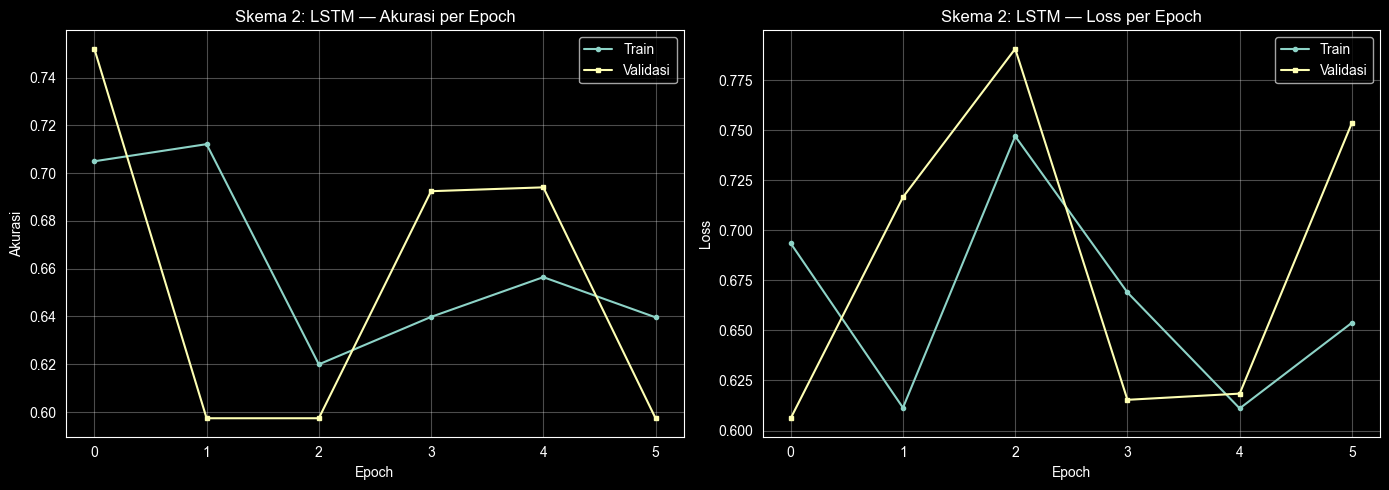

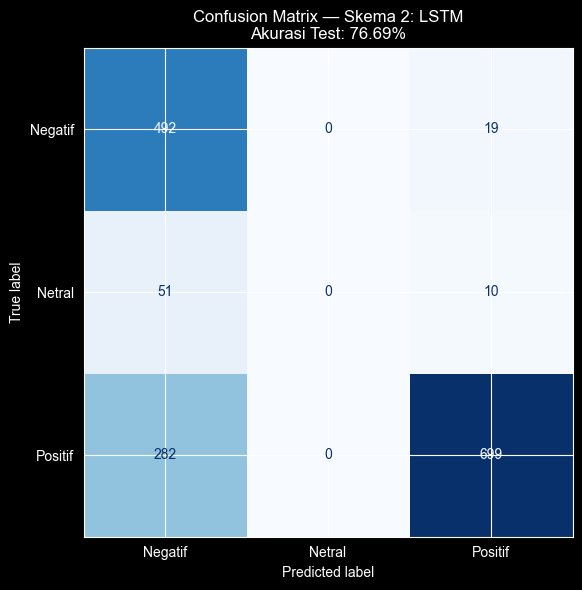

In [8]:
# Cell 8: Training curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train', marker='o', markersize=3)
axes[0].plot(history.history['val_accuracy'], label='Validasi', marker='s', markersize=3)
axes[0].set_title('Skema 2: LSTM \u2014 Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], label='Train', marker='o', markersize=3)
axes[1].plot(history.history['val_loss'], label='Validasi', marker='s', markersize=3)
axes[1].set_title('Skema 2: LSTM \u2014 Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/scheme2_training_curves.png', dpi=150)
plt.show()

# Confusion matrix
fig2, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix \u2014 Skema 2: LSTM\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme2_confusion_matrix.png', dpi=150)
plt.show()

In [9]:
# Cell 9: Save model
model_lstm.save('models/lstm_model.h5')
print("Saved: models/lstm_model.h5")
print("Saved: models/tokenizer.pkl (already saved in Cell 3)")
print("Saved: models/fasttext_model.bin (already saved in Cell 4)")

Saved: models/lstm_model.h5
Saved: models/tokenizer.pkl (already saved in Cell 3)
Saved: models/fasttext_model.bin (already saved in Cell 4)
